# 3. Training, validation and testing

Trains the U-Net, picks the model on validation regions, tests it on regions it never saw, and builds every table and figure of the report.

**Re-running this notebook does not retrain anything.** `RUN_TRAINING = False` skips the slow cells, and everything below them is computed from the small result files in `results/`.
Those files were copied from the real runs on Data Lab by `scripts/collect_results.py`. A full retrain needs the dataset and a GPU, and writes to your own `BASE` folder.

In [1]:
import os, sys, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "lulc").is_dir())
os.chdir(ROOT); sys.path.insert(0, str(ROOT / "src"))
RES = ROOT / "results"
plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110, "axes.grid": False})

# Where the exported data and full runs live. Set LULC_BASE to your own folder. Not needed to read or re-run this notebook.
BASE = os.environ.get("LULC_BASE", "/home/jovyan/vault/lulc" if Path("/home/jovyan/vault/lulc").is_dir() else str(ROOT / "data"))
OUT, RUNS, RUNS_MY = f"{BASE}/raw", f"{BASE}/runs", f"{BASE}/runs_multiyear"
PROJECT = os.environ.get("EE_PROJECT", "")     # your own Earth Engine project; no ID is stored in the repo
V12 = "V12_window3_balanced_stats"             # the shipped model

RUN_TRAINING = False     # True re-runs the slow steps below. They need Earth Engine and/or a GPU. Left False, nothing is downloaded or trained.
print("repo:", ROOT.name, "| data folder found:", Path(OUT).is_dir(), "|", "RUN_TRAINING =", RUN_TRAINING)

repo: sentinel1-lulc | data folder found: False | RUN_TRAINING = False


## Training
U-Net with a ResNet-34 encoder from ImageNet weights. Loss: class-weighted cross-entropy plus Dice. Exponential moving average of the weights, up to 12 epochs,
and early stopping on validation mIoU (patience 5). Every variant uses 3 seeds, and the shipped model averages its 3 seeds.

First the variants on 2021, then the final recipe on 2021 to 2024. Validation regions choose; test regions never do.

In [2]:
# Variants on 2021
if RUN_TRAINING:

    %run scripts/train_all.py --data $OUT --out $RUNS --variants V0_scratch_1m V1_imagenet_1m V5_window3_stats V6_window3_loss V7_window3_speckle V8_window3_all V9_window3_regularised V11_window3_balanced V12_window3_balanced_stats --workers 0

In [3]:
# The shipped model: V12 trained on 2021 to 2024, validated on 2024
if RUN_TRAINING:

    import shutil
    for v in ["V0_scratch_1m", "V1_imagenet_1m"]:     # the encoder-weights decision reads these scores; they are copies, not new training
        if os.path.isdir(f"{RUNS}/{v}") and not os.path.isdir(f"{RUNS_MY}/{v}"):
            shutil.copytree(f"{RUNS}/{v}", f"{RUNS_MY}/{v}")
    %run scripts/train_all.py --data $OUT --out $RUNS_MY --variants V12_window3_balanced_stats --seeds 0 1 2 --workers 0

**Saved log from the original run on Data Lab: training on 2021 to 2024.** This text is a copy of the real output, so it stays visible when the notebook is re-run.

```text
training years [2021, 2022, 2023, 2024], validation years [2024]
V12_window3_balanced_stats: encoder weights = imagenet (V0 0.466 vs V1 0.597)
loaded 84 train and 6 val regions
skip /home/jovyan/vault/lulc/runs_multiyear/V12_window3_balanced_stats/seed0
skip /home/jovyan/vault/lulc/runs_multiyear/V12_window3_balanced_stats/seed1
skip /home/jovyan/vault/lulc/runs_multiyear/V12_window3_balanced_stats/seed2
V16_window3_boundary: encoder weights = imagenet (V0 0.466 vs V1 0.597)
skip /home/jovyan/vault/lulc/runs_multiyear/V16_window3_boundary/seed0
skip /home/jovyan/vault/lulc/runs_multiyear/V16_window3_boundary/seed1
skip /home/jovyan/vault/lulc/runs_multiyear/V16_window3_boundary/seed2
Validation mIoU (gaps under 0.05 are inside seed noise):
                              mean    std  count
variant
V0_scratch_1m               0.466  0.010      3
V12_window3_balanced_stats  0.616  0.002      3
V16_window3_boundary        0.619  0.006      3
V1_imagenet_1m              0.597  0.008      3
```

## Testing
Three runs of the shipped model, with no-data months filled as the prototype does. Then package the 3 seeds into one file and copy the small result files.

In [4]:
if RUN_TRAINING:

    for y, tag in ((2021, "_2021_tolerant"), (2025, "_2025_filled"), (2026, "_2026_filled")):
        %run scripts/evaluate.py --data $OUT --runs $RUNS_MY --variant $V12 --year $y --skip-missing --tag $tag
    !python scripts/package_model.py --runs $RUNS_MY --variant $V12 --out weights --eval-tag _2021_tolerant
    !python scripts/collect_results.py --runs $RUNS $RUNS_MY --out results

# Results
From here on, each cell reads `results/` and writes to `results/tables/`, `docs/figures/` and `results/report_numbers.md`. No score is typed by hand.

How to read them:
- **2021 is a training year** for the shipped model, so that test is held out by place only. 2025 and 2026 are held out by place and by time.
- **Rows with different region counts are not comparable.** The independent maps exist for 9 regions only; use `same_regions_2021` for those.
- **Shipped rows in `test_2025_2026` use filled inputs; the two other models do not.** The like-for-like comparison, with no fill anywhere, is in `05_experiments.ipynb`.
- **`boundary_f1` mixes pooled and per-region values** (column `how`). Pooled values for all models are in `05_experiments.ipynb`.

In [5]:
import os, json, subprocess, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd() if (Path.cwd() / "configs").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
RES, FIG = ROOT / "results", ROOT / "docs" / "figures"
TAB = RES / "tables"
FIG.mkdir(parents=True, exist_ok=True); TAB.mkdir(parents=True, exist_ok=True)

SHIPPED = "V12_window3_balanced_stats"     # the model of the report
BOUNDARY = "V16_window3_boundary"          # the boundary-loss variant (reported as an ablation)
R21 = RES / "runs"                         # models trained on 2021 only
RMY = RES / "runs_multiyear"               # models trained on 2021-2024 (the shipped ensemble)
DATA = Path(os.environ.get("LULC_DATA", "/home/jovyan/vault/lulc/raw"))   # only needed for the class distribution and the orbit check

plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
NUMBERS = []                                # (section, text) lines for results/report_numbers.md

def need(path):
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f"{path} is missing. Run the training/evaluation notebooks, then scripts/collect_results.py, then this notebook.")
    return path

def jload(path): return json.loads(need(path).read_text())
def table(df, name, note=""):
    df.to_csv(TAB / f"{name}.csv", index=False)
    NUMBERS.append((name, note, df))
    return df

print("root:", ROOT.name)

root: sentinel1-lulc


## 1. Regions and splits

In [6]:
from lulc.config import load_config
label_year, regions = load_config(ROOT / "configs" / "regions.yaml")
rdf = pd.DataFrame([{"region": r.key, "split": r.split, "type": "city" if r.half_size_km > 6 else "rural", "side_km": 2 * r.half_size_km, "climate": r.climate} for r in regions])
splits = rdf.groupby(["split", "type"]).size().unstack(fill_value=0)
splits["total"] = splits.sum(axis=1)
splits = splits.reset_index()
display(table(splits, "splits", "Regions per split. Test regions are never used for training or model selection."))
print("Regions in total:", len(rdf), "| label year in config:", label_year)

type,split,city,rural,total
0,case_study,1,0,1
1,test,2,5,7
2,test_ood,3,29,32
3,train,10,11,21
4,val,2,4,6


Regions in total: 67 | label year in config: 2021


## 2. Class distribution of the training labels

In [7]:
from lulc.classes import CLASS_NAMES, N_CLASSES, remap_dynamic_world
cache = TAB / "class_distribution.csv"
if DATA.exists():
    counts = np.zeros(N_CLASSES)
    train_keys = [r.key for r in regions if r.split == "train"]
    n_files = 0
    for k in train_keys:
        for m in (1, 4, 7, 10):                     # four months spread over the year are enough for a share
            f = DATA / k / f"{label_year}-{m:02d}.npz"
            if f.exists():
                with np.load(f) as z:
                    lab = remap_dynamic_world(z["dw_label"])
                counts += np.bincount(lab[lab < N_CLASSES].ravel(), minlength=N_CLASSES)[:N_CLASSES]
                n_files += 1
    dist = pd.DataFrame({"class": CLASS_NAMES, "share_pct": 100 * counts / counts.sum()}).sort_values("share_pct", ascending=False)
    dist.to_csv(cache, index=False)
    print(f"Computed from {n_files} month files of {len(train_keys)} training regions (months 1, 4, 7, 10 of {label_year}); ignored pixels excluded.")
else:
    dist = pd.read_csv(need(cache))
    print("Data folder not found; using the saved table from the last run on Data Lab.")
dist["share_pct"] = dist["share_pct"].round(1)
display(table(dist, "class_distribution", "Share of labelled pixels in the training regions."))

Data folder not found; using the saved table from the last run on Data Lab.


,class,share_pct
0,Built-up,46.6
1,Cropland,18.0
2,Tree cover,17.8
3,Grass/shrub,7.1
4,Bare,6.2
5,Water,4.4


## 3. Orbit direction check

In [8]:
saved = RES / "orbit_check.txt"
if DATA.exists():
    out = subprocess.run([sys.executable, str(ROOT / "scripts" / "check_orbit.py"), "--data", str(DATA)], capture_output=True, text=True, cwd=ROOT)
    saved.write_text(out.stdout + out.stderr)
print(need(saved).read_text()[-2500:])

  2025  ASCENDING      12                1            2.0
         java_rice  2026  ASCENDING      10                0            2.0
     kazakh_steppe  2025 DESCENDING      12                3            3.5
madagascar_plateau  2021 DESCENDING      12                0            2.5
madagascar_plateau  2025 DESCENDING      12                0            2.5
            madrid  2023 DESCENDING      12                0            2.0
   mongolia_steppe  2022 DESCENDING      12               12            0.0
   mongolia_steppe  2023 DESCENDING      12               12            0.0
   mongolia_steppe  2024 DESCENDING      12               12            0.0
       nsw_pasture  2021 DESCENDING      12                0            2.5
       nsw_pasture  2022 DESCENDING      12                0            2.0
       nsw_pasture  2023 DESCENDING      12                0            2.5
       nsw_pasture  2024 DESCENDING      12                1            2.5
        nz_pasture  2021 DESCE

## 4. Variant comparison on the validation regions

In [9]:
rows = []
for root, tag in ((R21, "trained on 2021"), (RMY, "trained on 2021-2024")):
    for p in sorted(root.glob("*/seed*/summary.json")):
        if root == RMY and p.parent.parent.name in ("V0_scratch_1m", "V1_imagenet_1m"):
            continue          # copied from the 2021 runs for the encoder decision, not trained on 2021-2024
        j = json.loads(p.read_text()); rows.append({**j, "trained": tag})
need(R21)
sm = pd.DataFrame(rows)
var = sm.groupby(["trained", "variant"]).best_val_miou.agg(mean="mean", std="std", seeds="count").round(3).reset_index()
display(table(var, "variant_table", "Best validation mIoU per variant, mean and standard deviation over seeds. The two groups use different training and validation data, so compare variants only within a group."))
print("Standard deviation range:", var["std"].min(), "to", var["std"].max(), "| median", round(var["std"].median(), 3))

,trained,variant,mean,std,seeds
0,trained on 2021,V0_scratch_1m,0.466,0.010,3
1,trained on 2021,V11_window3_balanced,0.628,0.007,3
2,trained on 2021,V12_window3_balanced_stats,0.646,0.010,3
3,trained on 2021,V1_imagenet_1m,0.597,0.008,3
4,trained on 2021,V5_window3_stats,0.639,0.019,3
5,trained on 2021,V6_window3_loss,0.609,0.019,3
6,trained on 2021,V7_window3_speckle,0.633,0.003,3
7,trained on 2021,V8_window3_all,0.628,0.027,3
8,trained on 2021,V9_window3_regularised,0.604,0.026,3
9,trained on 2021-2024,V12_window3_balanced_stats,0.616,0.002,3


Standard deviation range: 0.001 to 0.027 | median 0.008


## 5. Training curves (Figure 1)

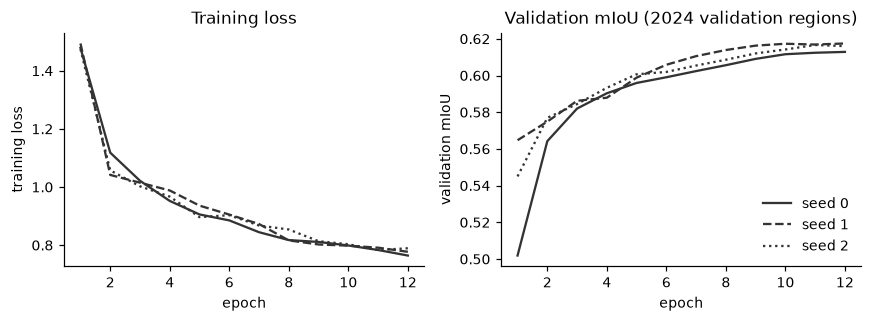

,seed,best_epoch,best_val_miou,epochs_run
0,seed0,12,0.613,12
1,seed1,12,0.617,12
2,seed2,11,0.617,12


In [10]:
fig, ax = plt.subplots(1, 2, figsize=(8, 3))
styles = {0: "-", 1: "--", 2: ":"}
hist_files = sorted((RMY / SHIPPED).glob("seed*/history.csv"))
if not hist_files:
    raise FileNotFoundError(f"No history.csv for {SHIPPED} in {RMY}. Run scripts/collect_results.py.")
for p in hist_files:
    s = int(p.parent.name.replace("seed", "")); h = pd.read_csv(p)
    ax[0].plot(h.epoch, h.train_loss, styles.get(s, "-"), color="0.2", label=f"seed {s}")
    ax[1].plot(h.epoch, h.val_miou, styles.get(s, "-"), color="0.2", label=f"seed {s}")
ax[0].set(xlabel="epoch", ylabel="training loss", title="Training loss")
ax[1].set(xlabel="epoch", ylabel="validation mIoU", title="Validation mIoU (2024 validation regions)")
ax[1].legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG / "fig1_training_curves.png", dpi=200); plt.show()
best = pd.DataFrame([{"seed": p.parent.name, "best_epoch": int(pd.read_csv(p).val_miou.idxmax()) + 1, "best_val_miou": round(pd.read_csv(p).val_miou.max(), 3), "epochs_run": len(pd.read_csv(p))} for p in hist_files])
display(table(best, "training_summary", "Best epoch per seed of the shipped model."))

## 6. Test on 2021: models trained on 2021, regions never seen

In [11]:
def eval_dir(runs, variant, tag=""): return need(runs / f"eval_{variant}{tag}")
# The shipped model is the multi-year ensemble. Its 2021 run (inference with filled gaps) replaces the 2021-only model here when it exists.
d21 = RMY / f"eval_{SHIPPED}_2021_tolerant"
if not d21.exists():
    print("NOT the shipped model: no eval_" + SHIPPED + "_2021_tolerant in results/runs_multiyear, using the 2021-only model")
    d21 = eval_dir(R21, SHIPPED)
print("2021 tables from:", d21.relative_to(ROOT))
m21 = jload(d21 / "metrics.json")
def score_rows(m, keys):
    return pd.DataFrame([{"set": k, "mIoU": round(m[k]["miou"], 3), "ci_low": round(m[k]["miou_lo"], 3), "ci_high": round(m[k]["miou_hi"], 3),
                          "OA": round(m[k]["oa"], 3), "regions": m[k]["n_cities"]} for k in keys if k in m])
sets = ["dw", "dw_cities", "dw_rural", "esri", "wc", "dw_wc_agree", "agree", "tolerant"]
labels = {"dw": "vs Dynamic World (all)", "dw_cities": "vs Dynamic World, cities", "dw_rural": "vs Dynamic World, rural", "esri": "vs Esri 2021 (independent)",
          "wc": "vs WorldCover 2021 (independent)", "dw_wc_agree": "vs Dynamic World, only where WorldCover agrees", "agree": "vs pixels WorldCover and Esri call the same",
          "tolerant": "correct if it matches Dynamic World, WorldCover or Esri (flatters any model; 9 regions only, so compare it in same_regions_2021, not with the first row)"}
t21 = score_rows(m21, sets); t21["set"] = t21["set"].map(labels)
display(table(t21, "test_2021", "Test 2021. The row 'only where WorldCover agrees' is the easier score some projects report; the main score is the first row."))
same = pd.read_csv(need(d21 / "per_city.csv"))
if "tolerant_miou" in same:
    same = same.dropna(subset=["tolerant_miou"])
    display(table(pd.DataFrame([{"regions": len(same), **{k: round(same[f"{k}_miou"].mean(), 3) for k in ("dw", "wc", "esri", "tolerant")}}]), "same_regions_2021",
                  "Mean per-region mIoU on the regions that have WorldCover and Esri maps, so these columns compare like with like. The pooled rows of test_2021 cover different regions."))
pc = pd.read_csv(need(d21 / "per_class.csv"))
pcd = pc[pc.set == "dw"][["class", "iou", "f1", "precision", "recall", "support_px"]].round(3)
display(table(pcd, "per_class_2021", "Per-class scores, test 2021, all regions pooled, vs Dynamic World."))

2021 tables from: results\runs_multiyear\eval_V12_window3_balanced_stats_2021_tolerant


,set,mIoU,ci_low,ci_high,OA,regions
0,vs Dynamic World (all),0.532,0.446,0.627,0.712,38
1,"vs Dynamic World, cities",0.474,0.377,0.601,0.765,5
2,"vs Dynamic World, rural",0.526,0.454,0.591,0.667,33
3,vs Esri 2021 (independent),0.668,0.524,0.716,0.843,9
4,vs WorldCover 2021 (independent),0.593,0.456,0.652,0.736,9
5,"vs Dynamic World, only where WorldCover agrees",0.791,0.633,0.845,0.919,9
6,vs pixels WorldCover and Esri call the same,0.798,0.632,0.862,0.924,9
7,"correct if it matches Dynamic World, WorldCove...",0.846,0.728,0.890,0.930,9


,regions,dw,wc,esri,tolerant
0,9,0.466,0.432,0.446,0.63


,class,iou,f1,precision,recall,support_px
0,Tree cover,0.563,0.720,0.661,0.791,81593233
1,Grass/shrub,0.350,0.518,0.493,0.546,81682418
2,Cropland,0.511,0.677,0.610,0.759,123789949
3,Built-up,0.833,0.909,0.936,0.883,153561013
4,Bare,0.455,0.625,0.722,0.551,63838076
5,Water,0.478,0.646,0.901,0.504,71067072


### Confusion matrix (Figure 2)

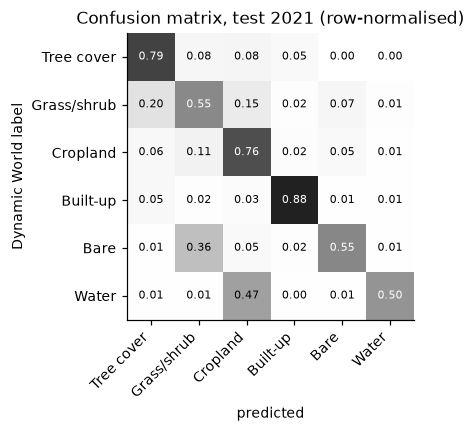

In [12]:
cm = np.array(m21["dw"]["confusion"], float)
norm = cm / cm.sum(axis=1, keepdims=True).clip(1)
fig, ax = plt.subplots(figsize=(4.6, 4))
im = ax.imshow(norm, cmap="Greys", vmin=0, vmax=1)
ax.set_xticks(range(len(CLASS_NAMES)), CLASS_NAMES, rotation=45, ha="right"); ax.set_yticks(range(len(CLASS_NAMES)), CLASS_NAMES)
for i in range(len(CLASS_NAMES)):
    for j in range(len(CLASS_NAMES)):
        ax.text(j, i, f"{norm[i, j]:.2f}", ha="center", va="center", color="white" if norm[i, j] > 0.5 else "black", fontsize=7)
ax.set(xlabel="predicted", ylabel="Dynamic World label", title="Confusion matrix, test 2021 (row-normalised)")
fig.tight_layout(); fig.savefig(FIG / "fig2_confusion_matrix.png", dpi=200); plt.show()

## 7. Worst and best regions, and the area warning

In [13]:
from scipy.stats import spearmanr
pcity = pd.read_csv(need(d21 / "per_city.csv"))
pcity = pcity.merge(rdf[["region", "type"]], on="region", how="left")
worst = pcity.sort_values("dw_miou")[["region", "type", "climate", "dw_miou", "dw_oa", "n_major_classes", "mean_conf"]].round(3)
display(table(worst.head(8), "worst_regions_2021", "Lowest-scoring test regions in 2021. One-class regions are flagged by n_major_classes."))
rho = spearmanr(pcity.mean_conf, pcity.dw_miou)[0]
print(f"Spearman(mean confidence, mIoU) over {len(pcity)} regions: {rho:.2f}")
NUMBERS.append(("spearman_2021", f"Rank correlation between mean confidence and mIoU, 2021: {rho:.2f}", None))

,region,type,climate,dw_miou,dw_oa,n_major_classes,mean_conf
21,sahel_niger,rural,arid,0.027,0.055,2,0.664
7,great_basin,rural,arid,0.069,0.312,3,0.538
24,patagonia_steppe,rural,southern_temperate,0.093,0.501,4,0.693
28,kazakh_steppe,rural,continental_crop,0.107,0.343,5,0.706
11,za_karoo_shrub,rural,southern_africa,0.125,0.662,3,0.896
27,iceland_tundra,rural,boreal,0.136,0.500,3,0.577
34,texas_rangeland,rural,arid,0.137,0.482,3,0.666
5,appalachians,rural,continental,0.149,0.826,3,0.887


Spearman(mean confidence, mIoU) over 38 regions: 0.50


## 8. Test on 2025 and 2026: unseen regions in unseen years

In [14]:
rows, cities = [], {}
for y in (2025, 2026):
    filled = f"_{y}_filled"          # inference with filled gaps, as the prototype runs; the older folder is the fallback
    shipped_tag = filled if (RMY / f"eval_{SHIPPED}{filled}").exists() else f"_y{y}"
    print(y, "shipped model from:", f"eval_{SHIPPED}{shipped_tag}")
    for name, runs, var, tag in [("trained on 2021 only", R21, SHIPPED, f"_y{y}_shipped"),
                                 ("trained on 2021-2024 (shipped)", RMY, SHIPPED, shipped_tag),
                                 ("trained on 2021-2024, boundary loss", RMY, BOUNDARY, f"_y{y}")]:
        d = runs / f"eval_{var}{tag}"
        if not d.exists():
            print("missing (skipped):", d.name); continue
        m = jload(d / "metrics.json")
        for k, lab in (("dw", "all"), ("dw_cities", "cities"), ("dw_rural", "rural")):
            if k in m:
                rows.append({"year": y, "model": name, "regions": lab, "mIoU": round(m[k]["miou"], 3), "ci_low": round(m[k]["miou_lo"], 3),
                             "ci_high": round(m[k]["miou_hi"], 3), "OA": round(m[k]["oa"], 3), "n": m[k]["n_cities"]})
        if name == "trained on 2021-2024 (shipped)":
            cities[y] = pd.read_csv(d / "per_city.csv")
t2526 = pd.DataFrame(rows)
if t2526.empty:
    raise FileNotFoundError("No 2025/2026 evaluation folders found in results/. Run the evaluation cell of multi_year.ipynb and collect_results.py.")
display(table(t2526, "test_2025_2026", "Pooled mIoU against Dynamic World of the same year. No independent map was used for these years."))

2025 shipped model from: eval_V12_window3_balanced_stats_2025_filled
2026 shipped model from: eval_V12_window3_balanced_stats_2026_filled


,year,model,regions,mIoU,ci_low,ci_high,OA,n
0,2025,trained on 2021 only,all,0.485,0.435,0.540,0.685,39
1,2025,trained on 2021 only,cities,0.465,0.402,0.563,0.751,5
2,2025,trained on 2021 only,rural,0.476,0.415,0.525,0.619,34
3,2025,trained on 2021-2024 (shipped),all,0.540,0.468,0.615,0.723,39
4,2025,trained on 2021-2024 (shipped),cities,0.489,0.378,0.600,0.781,5
5,2025,trained on 2021-2024 (shipped),rural,0.538,0.472,0.592,0.665,34
6,2025,"trained on 2021-2024, boundary loss",all,0.531,0.461,0.602,0.715,39
7,2025,"trained on 2021-2024, boundary loss",cities,0.495,0.391,0.598,0.782,5
8,2025,"trained on 2021-2024, boundary loss",rural,0.517,0.452,0.574,0.649,34
9,2026,trained on 2021 only,all,0.553,0.496,0.596,0.738,39


In [15]:
for y, c in cities.items():
    c = c.merge(rdf[["region", "type"]], on="region", how="left")
    multi = c[c.n_major_classes >= 2]
    rho = spearmanr(c.mean_conf, c.dw_miou)[0]
    print(f"{y}: worst regions: " + ", ".join(f"{r.region} {r.dw_miou:.3f}" for r in c.sort_values('dw_miou').head(5).itertuples()))
    print(f"{y}: Spearman(mean confidence, mIoU) {rho:.2f} over {len(c)} regions; regions with one major class: {(c.n_major_classes < 2).sum()}")

2025: worst regions: iceland_tundra 0.083, great_basin 0.086, sahel_niger 0.089, patagonia_steppe 0.102, texas_rangeland 0.148
2025: Spearman(mean confidence, mIoU) 0.52 over 39 regions; regions with one major class: 1
2026: worst regions: sahel_niger 0.069, texas_rangeland 0.085, patagonia_steppe 0.087, great_basin 0.101, iceland_tundra 0.104
2026: Spearman(mean confidence, mIoU) 0.37 over 39 regions; regions with one major class: 2


## 9. Class borders

In [16]:
rows = []
for y in (2025, 2026):
    filled = f"_{y}_filled"
    shipped_tag = filled if (RMY / f"eval_{SHIPPED}{filled}").exists() else f"_y{y}"
    for name, runs, var, tag in [("trained on 2021 only", R21, SHIPPED, f"_y{y}_shipped"), ("trained on 2021-2024 (shipped)", RMY, SHIPPED, shipped_tag),
                                 ("trained on 2021-2024, boundary loss", RMY, BOUNDARY, f"_y{y}")]:
        d = runs / f"eval_{var}{tag}"
        if not (d / "boundary.csv").exists():
            continue
        pooled = d / "boundary_pooled.json"
        if pooled.exists():
            j = json.loads(pooled.read_text()); rows.append({"year": y, "model": name, "boundary_F1_raw": round(j["bf1_raw"], 3), "boundary_F1_majority3": round(j["bf1_majority"], 3),
                                                              "pred_over_ref_border_px": round(j["pred_over_ref_border_px"], 2), "how": "pooled"})
        else:
            b = pd.read_csv(d / "boundary.csv")
            rows.append({"year": y, "model": name, "boundary_F1_raw": round(b.bf1_raw.mean(), 3), "boundary_F1_majority3": round(b.bf1_majority.mean(), 3),
                         "pred_over_ref_border_px": round(b.pred_border_px.sum() / max(b.ref_border_px.sum(), 1), 2), "how": "mean of regions (re-run evaluate.py for the pooled value)"})
bt = pd.DataFrame(rows)
display(table(bt, "boundary_f1", "Boundary F1 against Dynamic World, 1 pixel tolerance."))

,year,model,boundary_F1_raw,boundary_F1_majority3,pred_over_ref_border_px,how
0,2025,trained on 2021 only,0.219,0.220,0.70,mean of regions (re-run evaluate.py for the po...
1,2025,trained on 2021-2024 (shipped),0.344,0.346,0.69,pooled
2,2025,"trained on 2021-2024, boundary loss",0.248,0.249,0.78,mean of regions (re-run evaluate.py for the po...
3,2026,trained on 2021 only,0.232,0.236,0.75,mean of regions (re-run evaluate.py for the po...
4,2026,trained on 2021-2024 (shipped),0.369,0.371,0.74,pooled
5,2026,"trained on 2021-2024, boundary loss",0.265,0.269,0.85,mean of regions (re-run evaluate.py for the po...


## 10. False change on stable land

In [17]:
ch = pd.read_csv(need(d21 / "change.csv"))
ch = ch[ch.maps != "member_spread_pp_mean"]
fc = ch.groupby("maps")[["flip_rate_pct", "monthly_churn_pp", "net_total_change_pp"]].mean().round(2).reset_index()
display(table(fc, "false_change", f"Change on pixels both annual maps call stable, 2021, mean over {ch.region.nunique()} test regions."))
spread = pd.read_csv(d21 / "change.csv")
spread = spread[spread.maps == "member_spread_pp_mean"]
if len(spread):
    print("Mean seed spread of class shares (pp):", round(spread.monthly_churn_pp.mean(), 2))

,maps,flip_rate_pct,monthly_churn_pp,net_total_change_pp
0,dynamic_world,6.79,4.27,8.30
1,model,2.61,1.61,2.27
2,model+majority3,1.00,0.62,1.48


Mean seed spread of class shares (pp): 2.23


## 11. Score by calendar month

,month,OA,mIoU
0,1,0.678,0.501
1,2,0.715,0.526
2,3,0.731,0.540
3,4,0.662,0.498
4,5,0.696,0.491
5,6,0.712,0.518
6,7,0.719,0.540
7,8,0.705,0.526
8,9,0.740,0.561
9,10,0.740,0.564


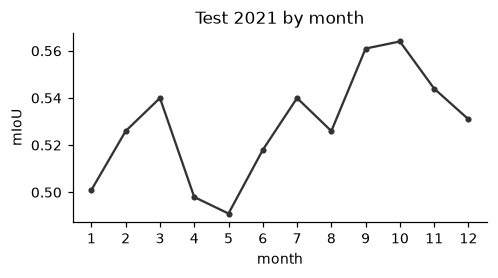

In [18]:
bm = pd.read_csv(need(d21 / "by_month.csv"), index_col=0).round(3).reset_index().rename(columns={"index": "month"})
display(table(bm[["month", "OA", "mIoU"]], "by_month_2021", "Pooled score per calendar month, test 2021."))
fig, ax = plt.subplots(figsize=(4.6, 2.6))
ax.plot(bm.month, bm.mIoU, "-o", color="0.2", ms=3); ax.set(xlabel="month", ylabel="mIoU", title="Test 2021 by month", xticks=range(1, 13))
fig.tight_layout(); fig.savefig(FIG / "fig4_by_month.png", dpi=200); plt.show()

## 12. Write all numbers to one file

In [19]:
def to_md(df):
    cols = list(df.columns)
    lines = ["| " + " | ".join(map(str, cols)) + " |", "| " + " | ".join("---" for _ in cols) + " |"]
    lines += ["| " + " | ".join(str(v) for v in row) + " |" for row in df.itertuples(index=False)]
    return "\n".join(lines)
out = ["# Report numbers (generated by notebooks/03_train_validate_test.ipynb, do not edit by hand)\n"]
for name, note, df in NUMBERS:
    out.append(f"## {name}\n\n{note}\n")
    if df is not None:
        out.append(to_md(df) + "\n")
(RES / "report_numbers.md").write_text("\n".join(out))
print("Wrote results/report_numbers.md with", len(NUMBERS), "blocks")

Wrote results/report_numbers.md with 13 blocks


**Next:** `04_app.ipynb`.